# Exercise 2: Computer Vision — Image Blending Using OpenCV

Objective: Apply basic image processing operations to merge visual inputs programmatically.

### Task Description:
1. Load two sample image files using OpenCV (`cv2`). Ensure both images are resized to matching dimensions if required.
2. Perform weighted image blending (`cv2.addWeighted`) to produce a composite blended image.
3. Display and save the two original input images alongside the resulting blended output image for verification.

### Import required libraries

In [6]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [7]:
img1_path = 'sample_image_1.jpg'
img2_path = 'sample_image_2.jpg'    

print(f"Using existing images: '{img1_path}' and '{img2_path}'")

Using existing images: 'sample_image_1.jpg' and 'sample_image_2.jpg'


### Task 1: Load Images & Resize to Matching Dimensions

In [8]:
# Load images in BGR format
img1 = cv2.imread(img1_path)
img2 = cv2.imread(img2_path)

if img1 is None or img2 is None:
    raise FileNotFoundError("One or both input image paths could not be loaded.")

print(f"Original Image 1 shape (H, W, C): {img1.shape}")
print(f"Original Image 2 shape (H, W, C): {img2.shape}")

# Resize img2 to match img1 dimensions
target_height, target_width = img1.shape[:2]
if img1.shape[:2] != img2.shape[:2]:
    img2_resized = cv2.resize(img2, (target_width, target_height), interpolation=cv2.INTER_AREA)
    print(f"Resized Image 2 shape (H, W, C):  {img2_resized.shape}")
else:
    img2_resized = img2.copy()
    print("Images already have matching dimensions.")

Original Image 1 shape (H, W, C): (3512, 6240, 3)
Original Image 2 shape (H, W, C): (4001, 6000, 3)
Resized Image 2 shape (H, W, C):  (3512, 6240, 3)


### Task 2: Perform Weighted Image Blending (`cv2.addWeighted`)
Blend the two images linearly according to:
$$\text{dst} = \alpha \cdot \text{img1} + \beta \cdot \text{img2} + \gamma$$
where $\alpha + \beta = 1.0$ and $\gamma = 0$.

In [9]:
# Define blending weights
alpha = 0.5   # Weight for Image 1
beta = 0.5    # Weight for Image 2 (1.0 - alpha)
gamma = 0.0   # Scalar added to each sum

# Perform weighted blending
blended_img = cv2.addWeighted(img1, alpha, img2_resized, beta, gamma)
print(f"Blended image created with alpha={alpha}, beta={beta}, gamma={gamma}.")

Blended image created with alpha=0.5, beta=0.5, gamma=0.0.


### Task 3: Display and Save Original & Blended Images
Convert images from OpenCV's default `BGR` color space to `RGB` for accurate rendering in Matplotlib, display all three images side-by-side, and save them to disk.

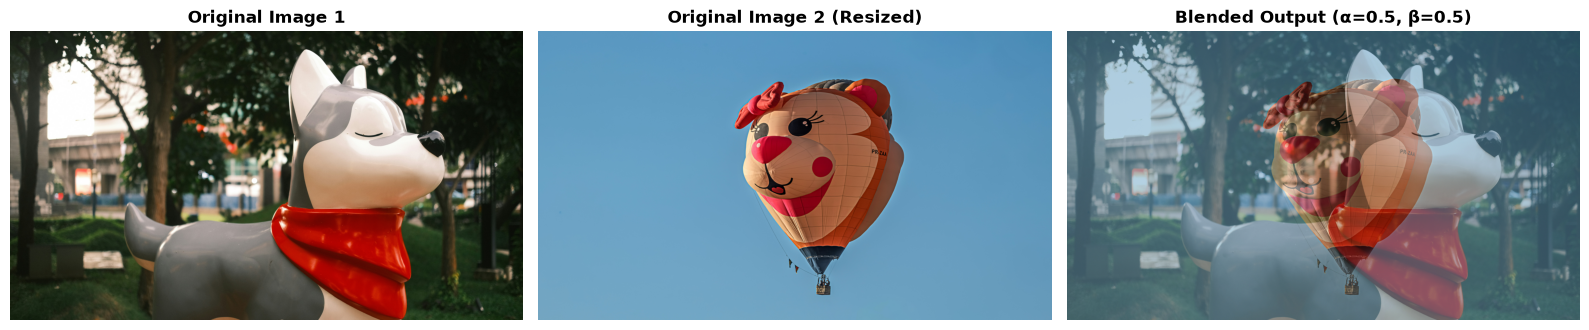

Saved files:
 - output_original_1.png
 - output_original_2_resized.png
 - output_blended_composite.png
 - comparison_grid.png


In [10]:
# Save the resized inputs and blended composite output to disk
cv2.imwrite('output_original_1.png', img1)
cv2.imwrite('output_original_2_resized.png', img2_resized)
cv2.imwrite('output_blended_composite.png', blended_img)

# Also save a combined side-by-side comparison figure
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

titles = [
    'Original Image 1',
    'Original Image 2 (Resized)',
    f'Blended Output (α={alpha}, β={beta})'
]
images_bgr = [img1, img2_resized, blended_img]

for ax, title, img_bgr in zip(axes, titles, images_bgr):
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    ax.imshow(img_rgb)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig('comparison_grid.png', dpi=150, bbox_inches='tight')
plt.show()

print("Saved files:")
print(" - output_original_1.png")
print(" - output_original_2_resized.png")
print(" - output_blended_composite.png")
print(" - comparison_grid.png")